Imports (STAGE 1)

In [4]:
import scipy.io as sio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import sqlite3 
import warnings
warnings.filterwarnings("ignore")
print("Library loaded successfully")

Library loaded successfully


Loading all four .mat files (Matlab files)

In [5]:
battery_files = {
    'B0005': '../data/raw/B0005.mat',
    'B0006': '../data/raw/B0006.mat',
    'B0007': '../data/raw/B0007.mat',
    'B0018': '../data/raw/B0018.mat',
}

raw_batteries = {}
for name, path in battery_files.items():
    mat = sio.loadmat(path, simplify_cells=True)
    raw_batteries[name] = mat[name]['cycle']
    print(f"{name}: {len(mat[name]['cycle'])} total cycles loaded")

B0005: 616 total cycles loaded
B0006: 616 total cycles loaded
B0007: 616 total cycles loaded
B0018: 319 total cycles loaded


Extracting all discharge cycles into one DataFrame

In [6]:
# EOL cutoff voltages differ per battery, from the README file
eol_voltage = {'B0005': 2.7, 'B0006': 2.5, 'B0007': 2.2, 'B0018': 2.5}

discharge_records = []

for battery_id, cycles in raw_batteries.items():
    discharge_num = 0
    for i, cycle in enumerate(cycles):
        if cycle['type'] != 'discharge':
            continue
        discharge_num += 1

        # Convert MATLAB time vector to Python datetime
        t = cycle['time']
        try:
            dt = datetime(int(t[0]), int(t[1]), int(t[2]),
                         int(t[3]), int(t[4]))
        except:
            dt = None

        data = cycle['data']
        voltage  = np.array(data['Voltage_measured'])
        current  = np.array(data['Current_measured'])
        temp     = np.array(data['Temperature_measured'])
        time_vec = np.array(data['Time'])

        discharge_records.append({
            'battery_id':          battery_id,
            'cycle_index':         i,
            'discharge_cycle_num': discharge_num,
            'datetime':            dt,
            'ambient_temp_c':      cycle['ambient_temperature'],
            'capacity_ahr':        data['Capacity'],
            'voltage_min':         voltage.min(),
            'voltage_max':         voltage.max(),
            'voltage_mean':        voltage.mean(),
            'temp_min_c':          temp.min(),
            'temp_max_c':          temp.max(),
            'temp_mean_c':         temp.mean(),
            'duration_secs':       time_vec.max(),
            'num_readings':        len(time_vec),
            'eol_cutoff_v':        eol_voltage[battery_id],
        })

discharge_df = pd.DataFrame(discharge_records)

print("Discharge DataFrame shape:", discharge_df.shape)
print("Columns:", discharge_df.columns.tolist())
print()
print(discharge_df.head(5))

Discharge DataFrame shape: (636, 15)
Columns: ['battery_id', 'cycle_index', 'discharge_cycle_num', 'datetime', 'ambient_temp_c', 'capacity_ahr', 'voltage_min', 'voltage_max', 'voltage_mean', 'temp_min_c', 'temp_max_c', 'temp_mean_c', 'duration_secs', 'num_readings', 'eol_cutoff_v']

  battery_id  cycle_index  discharge_cycle_num            datetime  \
0      B0005            1                    1 2008-04-02 15:25:00   
1      B0005            3                    2 2008-04-02 19:43:00   
2      B0005            5                    3 2008-04-03 00:01:00   
3      B0005            7                    4 2008-04-03 04:16:00   
4      B0005            9                    5 2008-04-03 08:33:00   

   ambient_temp_c  capacity_ahr  voltage_min  voltage_max  voltage_mean  \
0              24      1.856487     2.612467     4.191492      3.529829   
1              24      1.846327     2.587209     4.189773      3.537320   
2              24      1.835349     2.651917     4.188187      3.54373

Extract charge cycles

In [7]:
charge_records = []

for battery_id, cycles in raw_batteries.items():
    charge_num = 0
    for i, cycle in enumerate(cycles):
        if cycle['type'] != 'charge':
            continue
        charge_num += 1

        t = cycle['time']
        try:
            dt = datetime(int(t[0]), int(t[1]), int(t[2]),
                         int(t[3]), int(t[4]))
        except:
            dt = None

        data = cycle['data']
        voltage = np.array(data['Voltage_measured'])
        current = np.array(data['Current_measured'])
        temp    = np.array(data['Temperature_measured'])
        time_vec = np.array(data['Time'])

        charge_records.append({
            'battery_id':       battery_id,
            'cycle_index':      i,
            'charge_cycle_num': charge_num,
            'datetime':         dt,
            'ambient_temp_c':   cycle['ambient_temperature'],
            'voltage_max':      voltage.max(),
            'voltage_mean':     voltage.mean(),
            'current_mean':     current.mean(),
            'temp_max_c':       temp.max(),
            'temp_mean_c':      temp.mean(),
            'duration_secs':    time_vec.max(),
            'num_readings':     len(time_vec),
        })

charge_df = pd.DataFrame(charge_records)
print("Charge DataFrame shape:", charge_df.shape)
print("Columns:", charge_df.columns.tolist())
print()
print(charge_df.head(5))

Charge DataFrame shape: (644, 12)
Columns: ['battery_id', 'cycle_index', 'charge_cycle_num', 'datetime', 'ambient_temp_c', 'voltage_max', 'voltage_mean', 'current_mean', 'temp_max_c', 'temp_mean_c', 'duration_secs', 'num_readings']

  battery_id  cycle_index  charge_cycle_num            datetime  \
0      B0005            0                 1 2008-04-02 13:08:00   
1      B0005            2                 2 2008-04-02 16:37:00   
2      B0005            4                 3 2008-04-02 20:55:00   
3      B0005            6                 4 2008-04-03 01:12:00   
4      B0005            8                 5 2008-04-03 05:27:00   

   ambient_temp_c  voltage_max  voltage_mean  current_mean  temp_max_c  \
0              24     4.209949      4.187420      0.643455   27.445134   
1              24     4.213016      4.058826      0.949043   29.341949   
2              24     4.212788      4.058139      0.950529   29.553301   
3              24     4.212924      4.058905      0.952312   29.4563

Extract impedance cycles

In [8]:
impedance_records = []

for battery_id, cycles in raw_batteries.items():
    imp_num = 0
    for i, cycle in enumerate(cycles):
        if cycle['type'] != 'impedance':
            continue
        imp_num += 1

        t = cycle['time']
        try:
            dt = datetime(int(t[0]), int(t[1]), int(t[2]),
                         int(t[3]), int(t[4]))
        except:
            dt = None

        data = cycle['data']

        impedance_records.append({
            'battery_id':    battery_id,
            'cycle_index':   i,
            'imp_cycle_num': imp_num,
            'datetime':      dt,
            'Re_ohms':       data['Re'],
            'Rct_ohms':      data['Rct'],
        })

impedance_df = pd.DataFrame(impedance_records)
print("Impedance DataFrame shape:", impedance_df.shape)
print()
print(impedance_df.head(5))

Impedance DataFrame shape: (887, 6)

  battery_id  cycle_index  imp_cycle_num            datetime   Re_ohms  \
0      B0005           40              1 2008-04-18 20:55:00  0.044669   
1      B0005           42              2 2008-04-18 22:39:00  0.046687   
2      B0005           44              3 2008-04-19 02:14:00  0.044843   
3      B0005           46              4 2008-04-19 03:57:00  0.046195   
4      B0005           48              5 2008-04-19 07:32:00  0.045101   

   Rct_ohms  
0  0.069456  
1  0.076275  
2  0.067972  
3  0.074534  
4  0.068528  


FEATURE ENGINEERING (STAGE 2)

Adding KPI columns to discharge DataFrame

In [9]:
# Rated capacity for all batteries
RATED_CAPACITY = 2.0

# State of Health: current capacity as % of rated capacity
discharge_df['soh_pct'] = discharge_df['capacity_ahr'] / RATED_CAPACITY * 100

# Capacity fade from each battery's own first cycle
first_cap = discharge_df.groupby('battery_id')['capacity_ahr'].transform('first')
discharge_df['capacity_fade_pct'] = (first_cap - discharge_df['capacity_ahr']) / first_cap * 100

# EOL flag: True if capacity has dropped below 1.4 Ahr (threshold from README file)
discharge_df['is_past_eol'] = discharge_df['capacity_ahr'] < 1.4

# Discharge duration in minutes (makes it easier to read than seconds)
discharge_df['duration_mins'] = discharge_df['duration_secs'] / 60

# Rolling 10-cycle average capacity per battery (smooths noise)
discharge_df['capacity_rolling10'] = (
    discharge_df.groupby('battery_id')['capacity_ahr']
    .transform(lambda x: x.rolling(10, min_periods=1).mean())
)

# Cycle-over-cycle capacity change
discharge_df['capacity_change'] = (
    discharge_df.groupby('battery_id')['capacity_ahr'].diff()
)

# Week number from start of each battery's experiment
discharge_df['datetime'] = pd.to_datetime(discharge_df['datetime'])
start_dates = discharge_df.groupby('battery_id')['datetime'].transform('min')
discharge_df['days_elapsed'] = (discharge_df['datetime'] - start_dates).dt.days
discharge_df['week_num'] = discharge_df['days_elapsed'] // 7 + 1

print("Feature engineering complete")
print("New columns added:", ['soh_pct','capacity_fade_pct','is_past_eol',
      'duration_mins','capacity_rolling10','capacity_change',
      'days_elapsed','week_num'])
print()
print(discharge_df[['battery_id','discharge_cycle_num','capacity_ahr',
                    'soh_pct','capacity_fade_pct','is_past_eol']].head(10))

Feature engineering complete
New columns added: ['soh_pct', 'capacity_fade_pct', 'is_past_eol', 'duration_mins', 'capacity_rolling10', 'capacity_change', 'days_elapsed', 'week_num']

  battery_id  discharge_cycle_num  capacity_ahr    soh_pct  capacity_fade_pct  \
0      B0005                    1      1.856487  92.824371           0.000000   
1      B0005                    2      1.846327  92.316362           0.547279   
2      B0005                    3      1.835349  91.767460           1.138614   
3      B0005                    4      1.835263  91.763126           1.143282   
4      B0005                    5      1.834646  91.732275           1.176518   
5      B0005                    6      1.835662  91.783083           1.121783   
6      B0005                    7      1.835146  91.757307           1.149551   
7      B0005                    8      1.825757  91.287840           1.655310   
8      B0005                    9      1.824774  91.238693           1.708257   
9      

DATA QUALITY CHECK

In [10]:
# DATA QUALITY CHECK

for name, df, label in [
    ("discharge_df", discharge_df, "Discharge"),
    ("charge_df",    charge_df,    "Charge"),
    ("impedance_df", impedance_df, "Impedance"),
]:
    print(f"\n--- {label} Table ---")
    print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")


--- Discharge Table ---
Shape: 636 rows × 23 columns

--- Charge Table ---
Shape: 644 rows × 12 columns

--- Impedance Table ---
Shape: 887 rows × 6 columns


In [11]:
# Null check
nulls = df.isnull().sum()
null_cols = nulls[nulls > 0]
if len(null_cols) == 0:
    print("Nulls: NONE — all columns fully populated")
else:
    print("Nulls found:")
    print(null_cols)


Nulls: NONE — all columns fully populated


In [12]:
# Duplicate check
dupes = df.duplicated().sum()
if dupes == 0:
    print("Duplicates: NONE")
else:
    print(f"Duplicates found: {dupes} rows — investigate before proceeding")


Duplicates: NONE


In [13]:
# Data type summary
print("Column dtypes:")
print(df.dtypes.to_string())

# Numeric range check
print("\nNumeric column ranges:")
print(df.describe().round(4).to_string())

print("\n" + "=" * 50)
print("Quality check complete.")
print("=" * 50)

Column dtypes:
battery_id                  str
cycle_index               int64
imp_cycle_num             int64
datetime         datetime64[us]
Re_ohms                 float64
Rct_ohms                float64

Numeric column ranges:
       cycle_index  imp_cycle_num                    datetime   Re_ohms  Rct_ohms
count     887.0000       887.0000                         887  887.0000  887.0000
mean      315.8061       132.7779  2008-05-14 03:20:53.573844    0.0593    0.0828
min         1.0000         1.0000         2008-04-18 20:55:00    0.0359    0.0601
25%       172.0000        57.0000         2008-05-01 18:22:30    0.0506    0.0746
50%       310.0000       131.0000         2008-05-11 07:47:00    0.0596    0.0824
75%       460.0000       204.5000         2008-05-20 20:18:00    0.0658    0.0904
max       614.0000       278.0000         2008-08-20 01:34:00    0.0791    0.1067
std       168.5636        82.3900                         NaN    0.0098    0.0104

Quality check complete.


Saving all three DataFrames to CSV

In [14]:
discharge_df.to_csv('../data/clean/clean_discharge.csv', index=False)
charge_df.to_csv('../data/clean/clean_charge.csv', index=False)
impedance_df.to_csv('../data/clean/clean_impedance.csv', index=False)

print("Three clean files saved:")
print(f"  clean_discharge.csv — {discharge_df.shape[0]} rows, {discharge_df.shape[1]} columns")
print(f"  clean_charge.csv    — {charge_df.shape[0]} rows, {charge_df.shape[1]} columns")
print(f"  clean_impedance.csv — {impedance_df.shape[0]} rows, {impedance_df.shape[1]} columns")

Three clean files saved:
  clean_discharge.csv — 636 rows, 23 columns
  clean_charge.csv    — 644 rows, 12 columns
  clean_impedance.csv — 887 rows, 6 columns


 KPI CALCULATIONS (STAGE 3)

Printing all KPIs per battery

In [15]:
print("=" * 55)
print("BATTERY HEALTH KPI SUMMARY — ALL 4 BATTERIES")
print("=" * 55)

for b in ['B0005','B0006','B0007','B0018']:
    sub = discharge_df[discharge_df['battery_id'] == b]
    eol_cycles = sub[sub['is_past_eol']]

    print(f"\n{b}")
    print(f"  Total discharge cycles:     {len(sub)}")
    print(f"  Starting capacity (Ahr):    {sub.capacity_ahr.iloc[0]:.4f}")
    print(f"  Ending capacity (Ahr):      {sub.capacity_ahr.iloc[-1]:.4f}")
    print(f"  Starting SOH:               {sub.soh_pct.iloc[0]:.2f}%")
    print(f"  Ending SOH:                 {sub.soh_pct.iloc[-1]:.2f}%")
    print(f"  Total capacity fade:        {sub.capacity_fade_pct.iloc[-1]:.2f}%")
    print(f"  Avg fade per cycle (mAhr):  {(sub.capacity_ahr.iloc[0]-sub.capacity_ahr.iloc[-1])/len(sub)*1000:.3f}")
    print(f"  Crossed EOL (1.4 Ahr)?      {'Yes — cycle ' + str(eol_cycles.discharge_cycle_num.iloc[0]) if len(eol_cycles)>0 else 'No'}")
    print(f"  Cycles past EOL:            {len(eol_cycles)}")
    print(f"  Max discharge temp (C):     {sub.temp_max_c.max():.2f}")
    print(f"  Avg discharge duration:     {sub.duration_mins.mean():.1f} mins")

BATTERY HEALTH KPI SUMMARY — ALL 4 BATTERIES

B0005
  Total discharge cycles:     168
  Starting capacity (Ahr):    1.8565
  Ending capacity (Ahr):      1.3251
  Starting SOH:               92.82%
  Ending SOH:                 66.25%
  Total capacity fade:        28.62%
  Avg fade per cycle (mAhr):  3.163
  Crossed EOL (1.4 Ahr)?      Yes — cycle 125
  Cycles past EOL:            44
  Max discharge temp (C):     41.45
  Avg discharge duration:     52.2 mins

B0006
  Total discharge cycles:     168
  Starting capacity (Ahr):    2.0353
  Ending capacity (Ahr):      1.1857
  Starting SOH:               101.77%
  Ending SOH:                 59.28%
  Total capacity fade:        41.75%
  Avg fade per cycle (mAhr):  5.058
  Crossed EOL (1.4 Ahr)?      Yes — cycle 109
  Cycles past EOL:            59
  Max discharge temp (C):     42.01
  Avg discharge duration:     52.2 mins

B0007
  Total discharge cycles:     168
  Starting capacity (Ahr):    1.8911
  Ending capacity (Ahr):      1.4325
  Sta

EDA CHARTS (STAGE 4)

Chart 1: Capacity Fade Curve

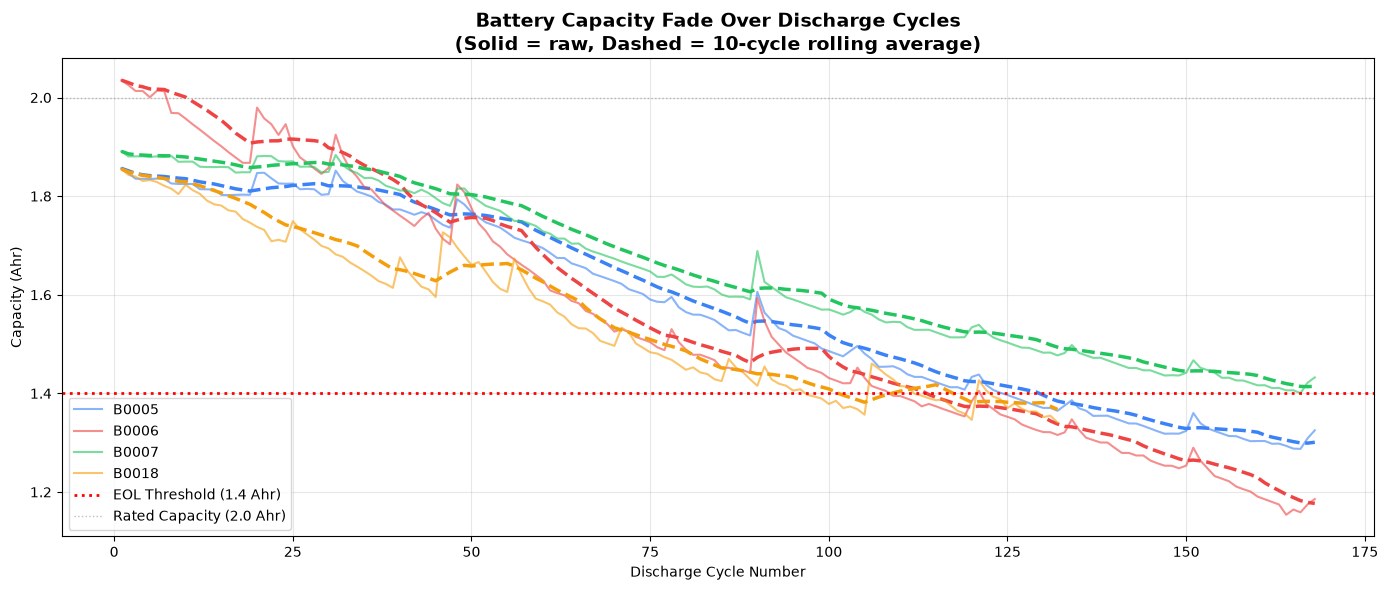

In [16]:
fig, ax = plt.subplots(figsize=(14, 6))

colors = {'B0005':'#3B82F6','B0006':'#EF4444','B0007':'#22C55E','B0018':'#F59E0B'}

for b in ['B0005','B0006','B0007','B0018']:
    sub = discharge_df[discharge_df['battery_id']==b]
    ax.plot(sub['discharge_cycle_num'], sub['capacity_ahr'],
            label=b, color=colors[b], linewidth=1.5, alpha=0.6)
    ax.plot(sub['discharge_cycle_num'], sub['capacity_rolling10'],
            color=colors[b], linewidth=2.5, linestyle='--')

# EOL threshold line
ax.axhline(1.4, color='red', linestyle=':', linewidth=2, label='EOL Threshold (1.4 Ahr)')
ax.axhline(2.0, color='gray', linestyle=':', linewidth=1, alpha=0.5, label='Rated Capacity (2.0 Ahr)')

ax.set_title("Battery Capacity Fade Over Discharge Cycles\n(Solid = raw, Dashed = 10-cycle rolling average)",
             fontsize=14, fontweight='bold')
ax.set_xlabel("Discharge Cycle Number")
ax.set_ylabel("Capacity (Ahr)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/chart1_capacity_fade.png', dpi=150, bbox_inches='tight')
plt.show()

Chart 2: State of Health (SOH) Over Time

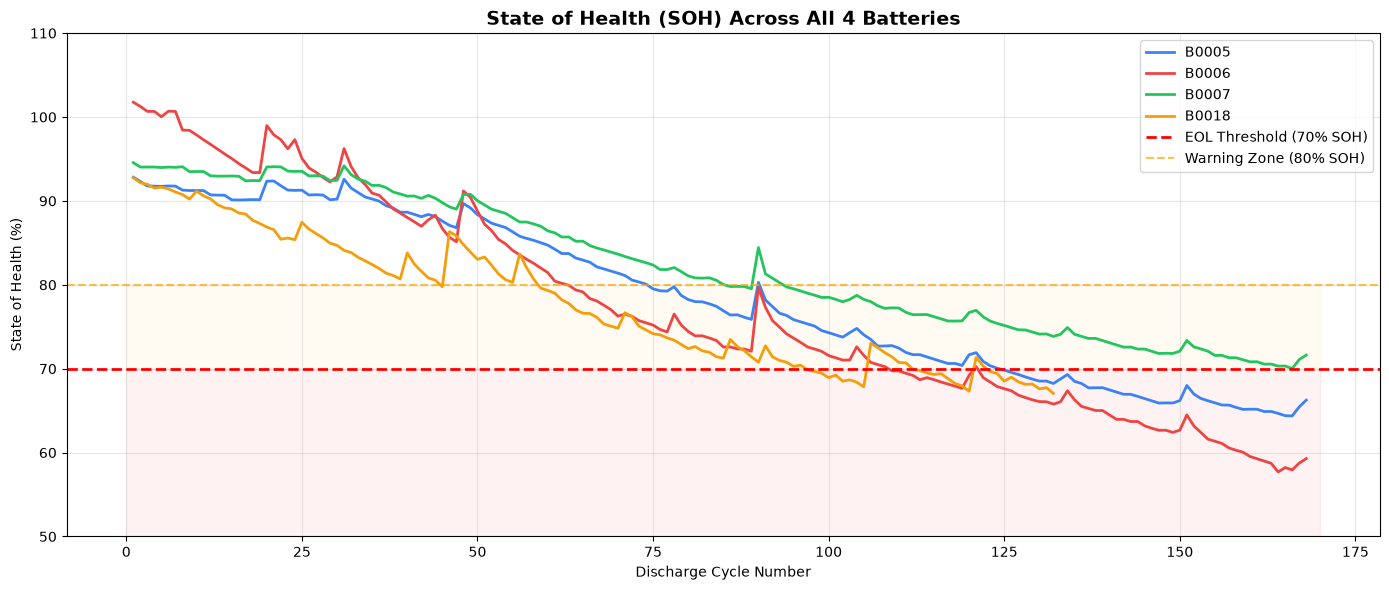

In [17]:
fig, ax = plt.subplots(figsize=(14, 6))

for b in ['B0005','B0006','B0007','B0018']:
    sub = discharge_df[discharge_df['battery_id']==b]
    ax.plot(sub['discharge_cycle_num'], sub['soh_pct'],
            label=b, color=colors[b], linewidth=2)

ax.axhline(70, color='red', linestyle='--', linewidth=2,
           label='EOL Threshold (70% SOH)')
ax.axhline(80, color='orange', linestyle='--', linewidth=1.5, alpha=0.7,
           label='Warning Zone (80% SOH)')

ax.fill_between([0,170], 0, 70, color='red', alpha=0.05)
ax.fill_between([0,170], 70, 80, color='orange', alpha=0.05)

ax.set_title("State of Health (SOH) Across All 4 Batteries",
             fontsize=14, fontweight='bold')
ax.set_xlabel("Discharge Cycle Number")
ax.set_ylabel("State of Health (%)")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(50, 110)
plt.tight_layout()
plt.savefig('../reports/chart2_soh_trend.png', dpi=150, bbox_inches='tight')
plt.show()

Chart 3: Internal Resistance Growth (Impedance)

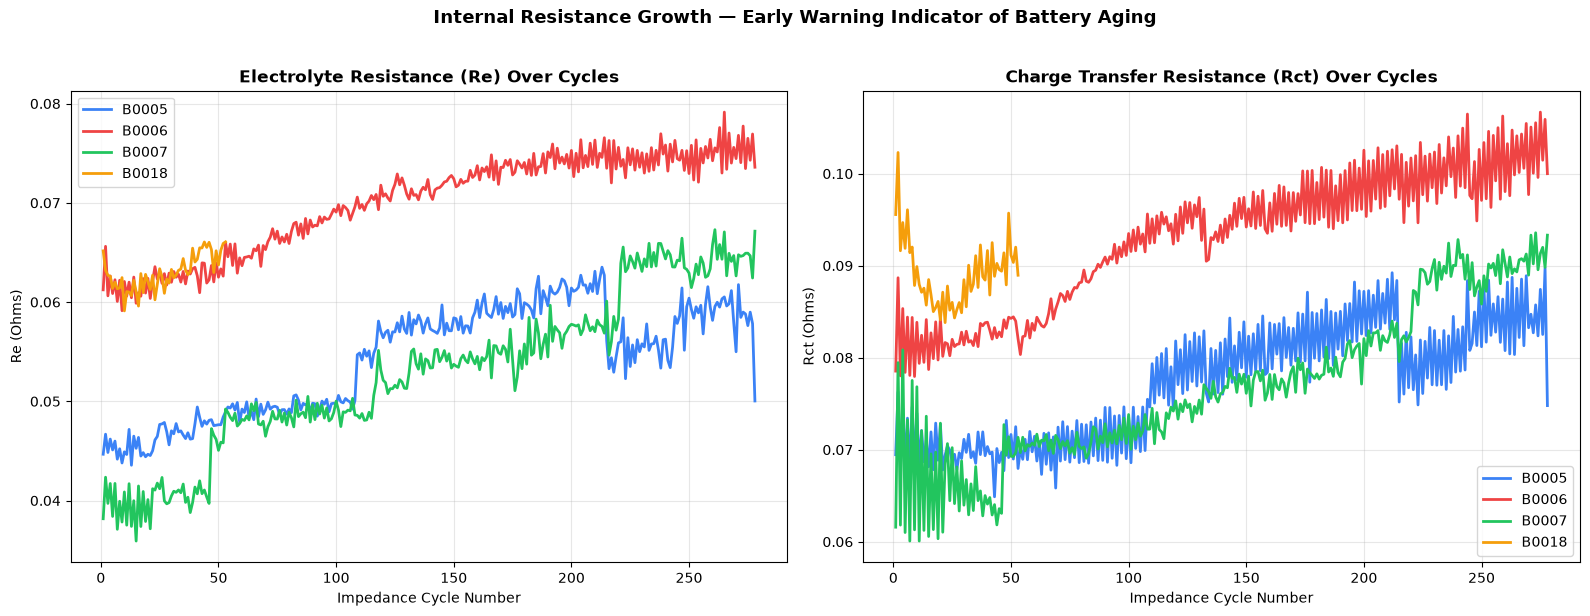

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for b in ['B0005','B0006','B0007','B0018']:
    sub = impedance_df[impedance_df['battery_id']==b]
    axes[0].plot(sub['imp_cycle_num'], sub['Re_ohms'],
                 label=b, color=colors[b], linewidth=2)
    axes[1].plot(sub['imp_cycle_num'], sub['Rct_ohms'],
                 label=b, color=colors[b], linewidth=2)

axes[0].set_title("Electrolyte Resistance (Re) Over Cycles",
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel("Impedance Cycle Number")
axes[0].set_ylabel("Re (Ohms)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Charge Transfer Resistance (Rct) Over Cycles",
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel("Impedance Cycle Number")
axes[1].set_ylabel("Rct (Ohms)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Internal Resistance Growth — Early Warning Indicator of Battery Aging",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/chart3_impedance_growth.png', dpi=150, bbox_inches='tight')
plt.show()

Chart 4: Temperature During Discharge Over Cycles

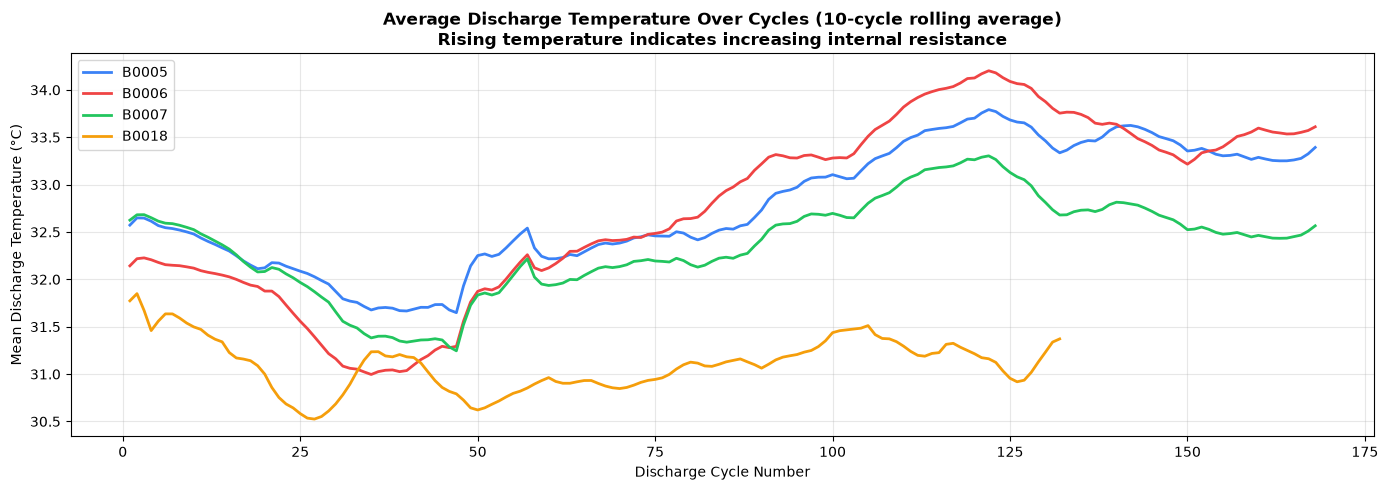

In [19]:
fig, ax = plt.subplots(figsize=(14, 5))

for b in ['B0005','B0006','B0007','B0018']:
    sub = discharge_df[discharge_df['battery_id']==b]
    rolling_temp = sub['temp_mean_c'].rolling(10, min_periods=1).mean()
    ax.plot(sub['discharge_cycle_num'], rolling_temp,
            label=b, color=colors[b], linewidth=2)

ax.set_title("Average Discharge Temperature Over Cycles (10-cycle rolling average)\nRising temperature indicates increasing internal resistance",
             fontsize=12, fontweight='bold')
ax.set_xlabel("Discharge Cycle Number")
ax.set_ylabel("Mean Discharge Temperature (°C)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/chart4_temperature_trend.png', dpi=150, bbox_inches='tight')
plt.show()

Chart 5: Discharge Duration Over Cycles

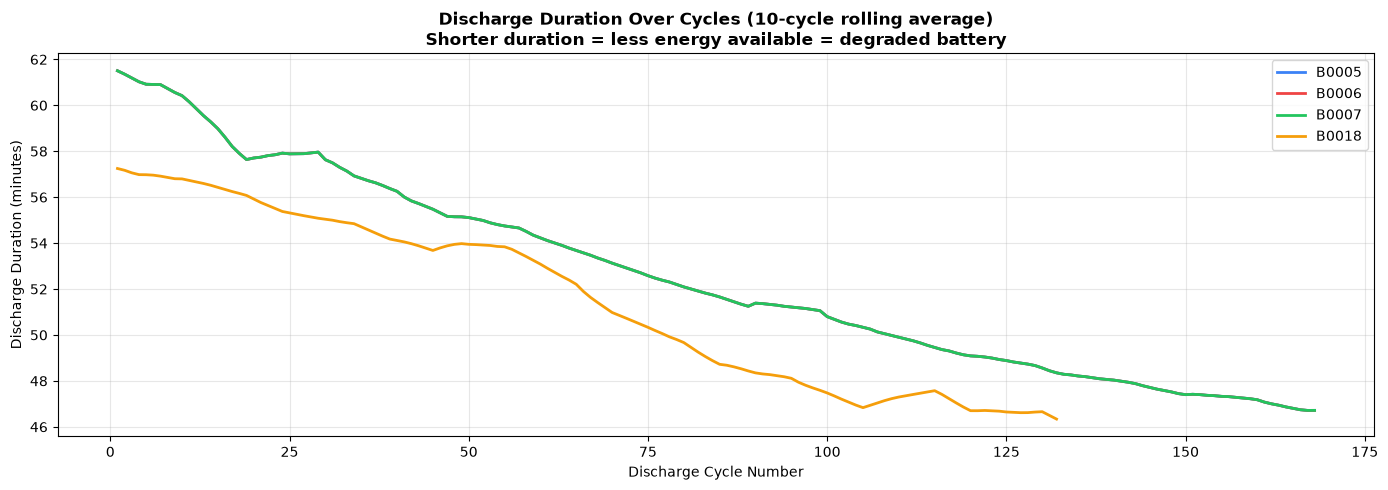

In [20]:
fig, ax = plt.subplots(figsize=(14, 5))

for b in ['B0005','B0006','B0007','B0018']:
    sub = discharge_df[discharge_df['battery_id']==b]
    rolling_dur = sub['duration_mins'].rolling(10, min_periods=1).mean()
    ax.plot(sub['discharge_cycle_num'], rolling_dur,
            label=b, color=colors[b], linewidth=2)

ax.set_title("Discharge Duration Over Cycles (10-cycle rolling average)\nShorter duration = less energy available = degraded battery",
             fontsize=12, fontweight='bold')
ax.set_xlabel("Discharge Cycle Number")
ax.set_ylabel("Discharge Duration (minutes)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/chart5_discharge_duration.png', dpi=150, bbox_inches='tight')
plt.show()

 LOAD INTO SQLITE

In [21]:
# Export to SQLite

conn = sqlite3.connect('../sql/bess.db')

discharge_df.to_sql('discharge', conn, if_exists='replace', index=False)
charge_df.to_sql('charge', conn, if_exists='replace', index=False)
impedance_df.to_sql('impedance', conn, if_exists='replace', index=False)

conn.close()

print("Database created: ../sql/bess.db")
print("Tables: discharge, charge, impedance")

Database created: ../sql/bess.db
Tables: discharge, charge, impedance
